# Semantic Similarity

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.1.2 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.1.2 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 'massi.egg-info/SOURCES.txt

In [2]:
import warnings

In [3]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [4]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=False


/tmp/ipykernel_8665/644029452.py:9: UserWarning: FAILED TO IMPORT `sentence_transformers`
  warnings.warn("FAILED TO IMPORT `sentence_transformers`")
/tmp/ipykernel_8665/644029452.py:10: UserWarning: No module named 'sentence_transformers'
  warnings.warn(str(e))


In [6]:
import tol_colors as tcls

In [7]:
import itertools as itlx
import json
from pathlib import Path
import re 

In [8]:
from IPython.display import display, display_markdown

In [9]:
from pprint import pprint

## Data Loading

In [10]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

In [11]:
%%sql
CREATE TABLE IF NOT EXISTS cons_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--cons_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,5934


In [12]:
%%sql
CREATE TABLE IF NOT EXISTS gt_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--gt_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,53666


In [13]:
display(conn.query("DESCRIBE gt_dwc_t_data_nodes;"))
display(conn.query("DESCRIBE gt_dwc_t_author_nodes;"))
display(conn.query("DESCRIBE gt_eml_data_nodes;"))
display(conn.query("DESCRIBE gt_eml_author_nodes;"))

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

In [34]:
%%sql 
SELECT COUNT(1) FROM cons_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8552


In [35]:
%%sql 
SELECT COUNT(1) FROM cons_dwc_t_author_nodes;

Running query in 'duckdb'

,count(1)
0,8562


In [36]:
%%sql 
SELECT COUNT(1) FROM cons_eml_data_nodes;

Running query in 'duckdb'

,count(1)
0,6369


In [38]:
%%sql 
SELECT COUNT(1) FROM cons_eml_author_nodes;

Running query in 'duckdb'

,count(1)
0,5934


## By Shared Ancestor Paths

### Confusion Matrix

In [15]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_data_nodes AS (
    SELECT  *, 
            c.text as cons_text, g.text as gt_text, 
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_data_nodes AS c 
    JOIN gt_dwc_t_data_nodes AS g
        ON  c.path = g.path 
        AND c.case_id = g.case_id
); 

Running query in 'duckdb'

,Count
0,8283


In [16]:
%sql SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8283


In [17]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_author_nodes AS (
    SELECT  *, 
            c.text as cons_text, g.text as gt_text, 
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_author_nodes AS c 
    JOIN gt_dwc_t_author_nodes AS g
        ON  c.path = g.path 
        AND c.case_id = g.case_id
); 

Running query in 'duckdb'

,Count
0,8254


In [18]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_data_nodes AS (
    SELECT  *, 
            c.text as cons_text, g.text as gt_text, 
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_data_nodes AS c 
    JOIN gt_eml_data_nodes AS g
        ON  c.path = g.path 
        AND c.case_id = g.case_id
); 

Running query in 'duckdb'

,Count
0,2844


In [19]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_author_nodes AS (
    SELECT  *, 
            c.text as cons_text, g.text as gt_text, 
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_author_nodes AS c 
    JOIN gt_eml_author_nodes AS g
        ON  c.path = g.path 
        AND c.case_id = g.case_id
); 

Running query in 'duckdb'

,Count
0,2760


#### Reporting Confusion Matrix

In [20]:
# text

In [21]:
%%sql 
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_data_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,8016,False,False
1,267,True,True


In [22]:
%%sql 
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_author_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,7984,False,False
1,270,True,True


In [23]:
%%sql 
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_data_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,1768,False,False
1,212,True,False
2,864,True,True


In [24]:
%%sql 
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_author_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,219,True,False
1,834,True,True
2,3,False,True
3,1704,False,False


In [25]:
# attributes

In [26]:
%%sql 
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_data_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,534,False,False
1,3,True,False
2,7746,True,True


In [28]:
%%sql 
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_author_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,540,False,False
1,3,True,False
2,7711,True,True


In [29]:
%%sql 
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_data_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,198,False,True
1,180,True,True
2,15,True,False
3,2451,False,False


In [30]:
%%sql 
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_author_nodes 
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,176,True,True
1,16,True,False
2,197,False,True
3,2371,False,False


### Computing Similarities

In [15]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [16]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1.0
    if not v1 or not v2:
        return None
    
    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [17]:
compute_cos_similarity("{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

1.0

In [18]:
ddb.create_function("cos_sim", compute_cos_similarity)

In [19]:
def wrap_text_struct(v: str) -> str:
    return json.dumps({"text": v})

In [20]:
ddb.create_function("wrap_text_struct", wrap_text_struct)

In [63]:
%%time
cons_gt_dwc_t_data_nodes_cos_sim = ddb.query("""
SELECT 
    c.case_id, c.path, 
    c.text as cons_t, g.text as gt_t, 
    -- wrap_text_struct(ifnull(c.text, '')) as cons_wrap_t, wrap_text_struct(ifnull(g.text, '')) as gt_wrap_t, 
    wrap_text_struct(c.text) as cons_wrap_t, wrap_text_struct(g.text) as gt_wrap_t, 
    c.attributes as cons_attributes, g.attributes as gt_attributes, 
    cos_sim(c.attributes, g.attributes) AS cos_sim_attrs, 
    cos_sim(wrap_text_struct(cons_wrap_t), wrap_text_struct(gt_wrap_t)) AS cos_sim_text
FROM cons_dwc_t_data_nodes AS c 
JOIN gt_dwc_t_data_nodes AS g
    ON  c.path = g.path 
    AND c.case_id = g.case_id
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 17.4 s, sys: 2.89 s, total: 20.3 s
Wall time: 31 s


In [64]:
cons_gt_dwc_t_data_nodes_cos_sim.describe(include="all")

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
count,8283.000000,8283,975,966,975,966,8283,8283,8283.000000,966.000000
unique,NaN,332,24,29,24,29,2868,2808,NaN,NaN
top,NaN,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},NaN,NaN
freq,NaN,174,267,260,267,260,534,537,NaN,NaN
mean,88.857781,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.933697,0.988593
std,51.662181,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.115382,0.044850
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.126419,0.692121
25%,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.885947,1.000000
50%,91.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000


In [65]:
cons_gt_dwc_t_data_nodes_cos_sim

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
0,0,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{'metadata': 'meta.xml'},{'metadata': 'eml.xml'},0.773793,1.000000
1,0,{http://rs.tdwg.org/dwc/text/}core,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{'rowType': 'http://rs.tdwg.org/dwc/terms/Occu...,"{'encoding': 'UTF-8', 'fieldsTerminatedBy': '\...",0.890905,1.000000
2,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},1.000000,1.000000
3,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,event.txt,"{""text"": ""occurrence.txt""}","{""text"": ""event.txt""}",{},{},1.000000,0.855316
4,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,NaN,NaN,NaN,NaN,{'index': '0'},{'index': '0'},1.000000,NaN
...,...,...,...,...,...,...,...,...,...,...
8278,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,NaN,NaN,NaN,NaN,"{'index': '26', 'term': 'http://rs.tdwg.org/dw...","{'index': '26', 'term': 'http://rs.tdwg.org/dw...",1.000000,NaN
8279,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,NaN,NaN,NaN,NaN,"{'index': '27', 'term': 'http://rs.tdwg.org/dw...","{'index': '27', 'term': 'http://rs.tdwg.org/dw...",1.000000,NaN
8280,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,NaN,NaN,NaN,NaN,"{'index': '28', 'term': 'http://rs.tdwg.org/dw...","{'index': '28', 'term': 'http://rs.tdwg.org/dw...",1.000000,NaN
8281,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,NaN,NaN,NaN,NaN,"{'index': '29', 'term': 'http://rs.tdwg.org/dw...","{'index': '29', 'term': 'http://rs.tdwg.org/dw...",1.000000,NaN


In [66]:
%%time
cons_gt_dwc_t_author_nodes_cos_sim = ddb.query("""
SELECT 
    c.case_id, c.path, 
    c.text as cons_t, g.text as gt_t, 
    -- wrap_text_struct(ifnull(c.text, '')) as cons_wrap_t, wrap_text_struct(ifnull(g.text, '')) as gt_wrap_t, 
    wrap_text_struct(c.text) as cons_wrap_t, wrap_text_struct(g.text) as gt_wrap_t, 
    c.attributes as cons_attributes, g.attributes as gt_attributes, 
    cos_sim(c.attributes, g.attributes) AS cos_sim_attrs, 
    cos_sim(wrap_text_struct(cons_wrap_t), wrap_text_struct(gt_wrap_t)) AS cos_sim_text
FROM cons_dwc_t_author_nodes AS c 
JOIN gt_dwc_t_author_nodes AS g
    ON  c.path = g.path 
    AND c.case_id = g.case_id
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 19.2 s, sys: 3.12 s, total: 22.3 s
Wall time: 34 s


In [67]:
%%time
cons_gt_eml_data_nodes_cos_sim = ddb.query("""
SELECT 
    c.case_id, c.path, 
    c.text as cons_t, g.text as gt_t, 
    -- wrap_text_struct(ifnull(c.text, '')) as cons_wrap_t, wrap_text_struct(ifnull(g.text, '')) as gt_wrap_t, 
    wrap_text_struct(c.text) as cons_wrap_t, wrap_text_struct(g.text) as gt_wrap_t, 
    c.attributes as cons_attributes, g.attributes as gt_attributes, 
    cos_sim(c.attributes, g.attributes) AS cos_sim_attrs, 
    cos_sim(wrap_text_struct(cons_wrap_t), wrap_text_struct(gt_wrap_t)) AS cos_sim_text
FROM cons_eml_data_nodes AS c 
JOIN gt_eml_data_nodes AS g
    ON  c.path = g.path 
    AND c.case_id = g.case_id
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 42.9 s, sys: 13.8 s, total: 56.7 s
Wall time: 38.4 s


In [68]:
%%time
cons_gt_eml_author_nodes_cos_sim = ddb.query("""
SELECT 
    c.case_id, c.path, 
    c.text as cons_t, g.text as gt_t, 
    -- wrap_text_struct(ifnull(c.text, '')) as cons_wrap_t, wrap_text_struct(ifnull(g.text, '')) as gt_wrap_t, 
    wrap_text_struct(c.text) as cons_wrap_t, wrap_text_struct(g.text) as gt_wrap_t, 
    c.attributes as cons_attributes, g.attributes as gt_attributes, 
    cos_sim(c.attributes, g.attributes) AS cos_sim_attrs, 
    cos_sim(wrap_text_struct(cons_wrap_t), wrap_text_struct(gt_wrap_t)) AS cos_sim_text
FROM cons_eml_author_nodes AS c 
JOIN gt_eml_author_nodes AS g
    ON  c.path = g.path 
    AND c.case_id = g.case_id
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 42.6 s, sys: 13.6 s, total: 56.2 s
Wall time: 38 s


#### Report Similarities

In [69]:
cons_gt_dwc_t_data_nodes_cos_sim.describe(include="all")

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
count,8283.000000,8283,975,966,975,966,8283,8283,8283.000000,966.000000
unique,NaN,332,24,29,24,29,2868,2808,NaN,NaN
top,NaN,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},NaN,NaN
freq,NaN,174,267,260,267,260,534,537,NaN,NaN
mean,88.857781,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.933697,0.988593
std,51.662181,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.115382,0.044850
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.126419,0.692121
25%,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.885947,1.000000
50%,91.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000
75%,134.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000


<Axes: ylabel='Frequency'>

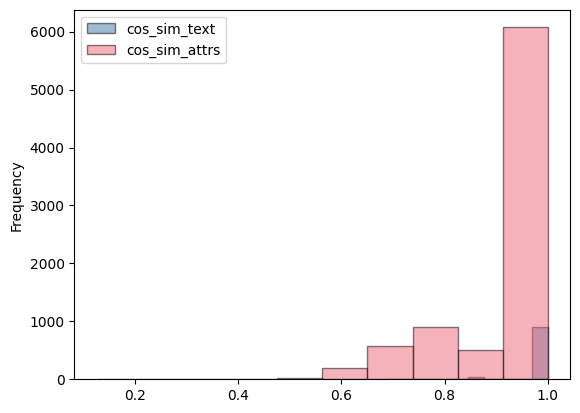

In [70]:
cons_gt_dwc_t_data_nodes_cos_sim["cos_sim_text"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)
cons_gt_dwc_t_data_nodes_cos_sim["cos_sim_attrs"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)

In [71]:
cons_gt_dwc_t_author_nodes_cos_sim.describe(include="all")

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
count,8254.000000,8254,984,975,984,975,8254,8254,8254.000000,975.000000
unique,NaN,330,23,28,23,28,2829,2762,NaN,NaN
top,NaN,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},NaN,NaN
freq,NaN,174,270,263,270,263,540,543,NaN,NaN
mean,89.336079,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.924626,0.985245
std,50.617869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.122398,0.051043
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.136131,0.692121
25%,46.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.842089,1.000000
50%,91.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000
75%,133.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000


<Axes: ylabel='Frequency'>

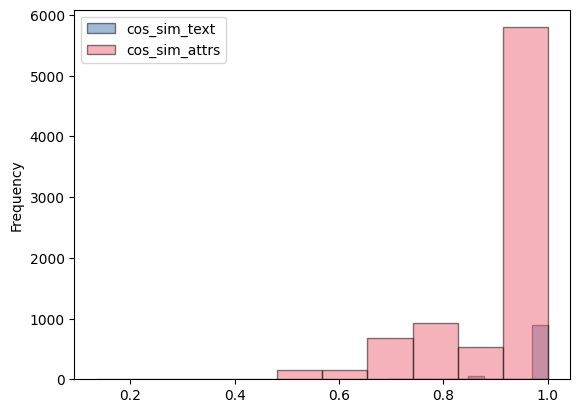

In [72]:
cons_gt_dwc_t_author_nodes_cos_sim["cos_sim_text"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)
cons_gt_dwc_t_author_nodes_cos_sim["cos_sim_attrs"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)

In [73]:
cons_gt_eml_data_nodes_cos_sim.describe(include="all")

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
count,2844.000000,2844,2797,2688,2797,2688,2844,2844,2844.000000,2641.000000
unique,NaN,106,403,636,403,636,80,206,NaN,NaN
top,NaN,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},NaN,NaN
freq,NaN,150,539,308,539,308,2649,2466,NaN,NaN
mean,85.343530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.924282,0.876110
std,53.154125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.202199,0.207493
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.153541,0.015169
25%,40.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.748774
50%,83.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000
75%,132.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000


<Axes: ylabel='Frequency'>

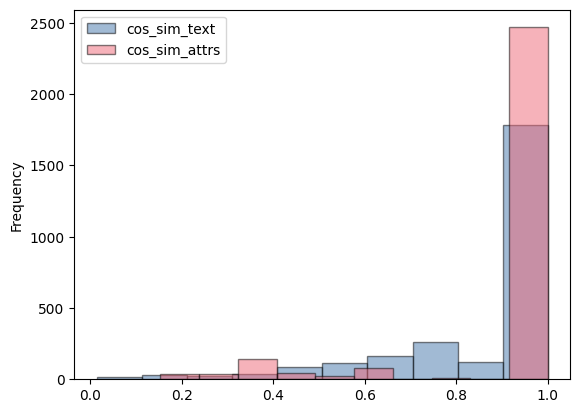

In [74]:
cons_gt_eml_data_nodes_cos_sim["cos_sim_text"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)
cons_gt_eml_data_nodes_cos_sim["cos_sim_attrs"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)

In [75]:
cons_gt_eml_author_nodes_cos_sim.describe(include="all")

,case_id,path,cons_t,gt_t,cons_wrap_t,gt_wrap_t,cons_attributes,gt_attributes,cos_sim_attrs,cos_sim_text
count,2760.000000,2760,2703,2609,2703,2609,2760,2760,2760.000000,2552.000000
unique,NaN,68,561,628,561,628,87,206,NaN,NaN
top,NaN,.,\n,\n,"{""text"": ""\n ""}","{""text"": ""\n ""}",{},{},NaN,NaN
freq,NaN,148,514,286,514,286,2568,2387,NaN,NaN
mean,90.430435,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.922567,0.891237
std,51.683751,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.204580,0.187241
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.120994,0.026708
25%,47.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.787306
50%,89.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000
75%,139.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000


<Axes: ylabel='Frequency'>

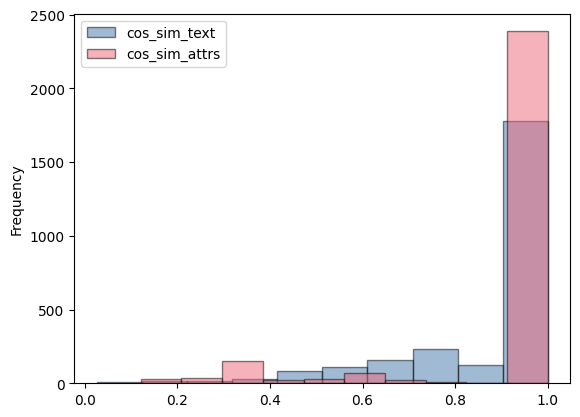

In [76]:
cons_gt_eml_author_nodes_cos_sim["cos_sim_text"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)
cons_gt_eml_author_nodes_cos_sim["cos_sim_attrs"].plot.hist(alpha=0.5, ls="-", lw=1, edgecolor="k", legend=True)

In [77]:
cons_gt_eml_author_nodes_cos_sim.groupby(by="case_id").describe(include="all")

path                                                ... cos_sim_text  \
        count unique top freq mean  std  min  25%  50%  75%  ...       unique   
case_id                                                      ...                
0          31     31   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
3          23     23   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
4          32     32   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
5          23     23   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
6          26     26   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
...       ...    ...  ..  ...  ...  ...  ...  ...  ...  ...  ...          ...   
172        16     16   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
174        22     22   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
175         9      9   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
176        15     15   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   
178        13     13   .    1  NaN  NaN  NaN  NaN  NaN  NaN  ...          NaN   

                                                                         
        top freq      mean       std       min       25%  50%  75%  max  
case_id                                                                  
0       NaN  NaN  0.820648  0.258458  0.103202  0.739207  1.0  1.0  1.0  
3       NaN  NaN  0.899206  0.164173  0.427052  0.759917  1.0  1.0  1.0  
4       NaN  NaN  0.853356  0.205620  0.173113  0.698017  1.0  1.0  1.0  
5       NaN  NaN  0.860270  0.212685  0.167688  0.747822  1.0  1.0  1.0  
6       NaN  NaN  0.910481  0.176136  0.308761  0.844777  1.0  1.0  1.0  
...      ..  ...       ...       ...       ...       ...  ...  ...  ...  
172     NaN  NaN  0.969112  0.077891  0.748138  1.000000  1.0  1.0  1.0  
174     NaN  NaN  0.857109  0.265201  0.067238  0.758151  1.0  1.0  1.0  
175     NaN  NaN  0.929008  0.149237  0.578226  0.957833  1.0  1.0  1.0  
176     NaN  NaN  0.866266  0.213340  0.401074  0.797393  1.0  1.0  1.0  
178     NaN  NaN  0.947588  0.108607  0.712076  0.991562  1.0  1.0  1.0  

[148 rows x 99 columns]

In [48]:
cons_gt_dwc_t_data_nodes_cos_sim.to_csv("procedural_data/raw_cons_gt_dwc_t_data_nodes_cos_sim.csv")
cons_gt_dwc_t_author_nodes_cos_sim.to_csv("procedural_data/raw_cons_gt_dwc_t_author_nodes_cos_sim.csv")
cons_gt_eml_data_nodes_cos_sim.to_csv("procedural_data/raw_cons_gt_eml_data_nodes_cos_sim.csv")
cons_gt_eml_author_nodes_cos_sim.to_csv("procedural_data/raw_cons_gt_eml_author_nodes_cos_sim.csv")